In [40]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RANDOM_STATE = 505
YEARS = range(2015, 2024)
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60)

# ADS 505: Which ATP match statistics are associated with winning?
**Team:** Ryan Salas and Meeki Mee  
**Team GitHub repository:** https://github.com/ryan-salas/ADS-505-Tennis-Analytics

**Status:** Business framing, cleaning, EDA, and modeling-data preparation completed; modeling pending.

## 1. Business Problem and Project Objectives

A tennis coaching organization has limited training time and resources.
Its director of player development needs evidence to determine which
performance areas deserve the most attention.

This project analyzes ATP matches from 2015–2023 to answer:
Which match-performance statistics are most strongly associated with
winning, and how can coaches use those findings to prioritize training?

We will examine first-serve percentage, first-serve points won,
second-serve points won, aces, double faults, and break-point performance.
We will also investigate whether these relationships differ by court surface.

The business objective is to develop an understandable performance-review
framework that helps coaches identify training priorities and prepare
players for competition. Recommendations will connect the analysis to
specific coaching decisions.

Success will be measured by whether the analysis identifies useful,
consistent performance indicators, improves classification over a simple
baseline, and produces clear recommendations for coaching staff.

Because the statistics describe completed matches, this project supports
post-match performance review. It does not forecast outcomes before play
begins. Associations will be interpreted cautiously: they do not establish
that improving a particular statistic causes more wins.

## 2. Data source and download
Source: https://github.com/migumax/tennis_atp (master branch), a fork of the
TennisMyLife database. Each file is named by year, such as `2015.csv`.
The source supplies one row per match, with separate winner and loser fields.
The supplied local files are reused; missing files are downloaded below.
`data_manifest.json` records the included snapshot hashes and retrieval time.
For exact reproduction, retain these downloaded files because master can change.

Working dataset reference: migumax. (n.d.). *tennis_atp* [Data set]. GitHub.
https://github.com/migumax/tennis_atp. Acknowledge TennisMyLife and ATP as
underlying sources. Review the repository's usage terms before redistributing
raw data; the supplied `.gitignore` excludes raw files from GitHub commits.

In [41]:
frames = []
for year in YEARS:
    file_path = RAW_DIR / f"{year}.csv"
    if not file_path.exists():
        url = (
            "https://raw.githubusercontent.com/migumax/"
            f"tennis_atp/master/{year}.csv"
        )
        with urlopen(url, timeout=60) as response:
            payload = response.read()
        # Validate downloaded content before writing it to disk.
        if not payload.startswith(b"tourney_id,"):
            raise ValueError(f"Unexpected CSV content for {year}")
        file_path.write_bytes(payload)
    yearly = pd.read_csv(file_path)
    yearly["source_year"] = year
    frames.append(yearly)

matches_raw = pd.concat(frames, ignore_index=True)
assert set(matches_raw["source_year"]) == set(YEARS)
print(f"Loaded {len(matches_raw):,} matches.")
display(matches_raw.head())

Loaded 24,697 matches.


,tourney_id,tourney_name,surface,draw_size,tourney_level,indoor,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,winner_rank,winner_rank_points,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,loser_rank,loser_rank_points,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,source_year
0,2015-339,Brisbane,Hard,28,250,O,20150104,1,MH30,NaN,WC,John Millman,R,183.0,AUS,25.558,153.0,328.0,W522,NaN,Q,Rhyne Williams,R,185.0,USA,23.789,220.0,221.0,6-3 6-1,3,R32,65.0,6.0,2.0,44.0,24.0,19.0,14.0,8.0,1.0,1.0,3.0,4.0,50.0,31.0,20.0,5.0,8.0,1.0,5.0,2015
1,2015-339,Brisbane,Hard,28,250,O,20150104,2,KD46,NaN,WC,Thanasi Kokkinakis,R,193.0,AUS,18.735,149.0,341.0,B747,8.0,NaN,Julien Benneteau,R,185.0,FRA,33.040,25.0,1365.0,6-4 6-3,3,R32,75.0,9.0,1.0,52.0,30.0,25.0,14.0,10.0,1.0,2.0,5.0,3.0,52.0,33.0,23.0,7.0,9.0,1.0,4.0,2015
2,2015-339,Brisbane,Hard,28,250,O,20150104,3,TA46,NaN,NaN,Bernard Tomic,R,196.0,AUS,22.204,53.0,797.0,Q927,NaN,NaN,Sam Querrey,R,198.0,USA,27.244,35.0,1090.0,7-5 7-6(5),3,R32,83.0,5.0,0.0,77.0,46.0,36.0,21.0,12.0,4.0,5.0,20.0,3.0,70.0,42.0,35.0,14.0,12.0,4.0,6.0,2015
3,2015-339,Brisbane,Hard,28,250,O,20150104,4,J386,NaN,NaN,Steve Johnson,R,188.0,USA,25.029,37.0,999.0,ME05,NaN,NaN,Marinko Matosevic,R,193.0,AUS,29.407,77.0,657.0,2-6 7-6(0) 7-5,3,R32,136.0,14.0,3.0,95.0,58.0,45.0,24.0,16.0,4.0,6.0,10.0,5.0,106.0,68.0,51.0,19.0,16.0,3.0,4.0,2015
4,2015-339,Brisbane,Hard,28,250,O,20150104,5,N289,NaN,NaN,Jarkko Nieminen,L,185.0,FIN,33.451,73.0,689.0,KB09,NaN,Q,Denis Kudla,R,180.0,USA,22.382,123.0,440.0,4-6 6-1 6-4,3,R32,104.0,4.0,0.0,92.0,59.0,39.0,17.0,14.0,4.0,7.0,6.0,1.0,83.0,50.0,26.0,19.0,13.0,3.0,8.0,2015


### Business relevance of the dataset

The dataset contains ATP match records from 2015–2023, including match
outcomes, court surfaces, player characteristics, and serving statistics.
These records provide a foundation for examining which performance
indicators are associated with winning.

The intended users are a head coach and director of player development.
The analysis will help them evaluate player performances and identify
areas to investigate when allocating training time.

Each row contains a match record with separate winner and loser
statistics. We must restructure these fields before modeling so the
model cannot identify the outcome from the column labels.

The data represents professional men's tennis. Recommendations may
not transfer directly to recreational, junior, or women's tennis.

### Variable guide
- `tourney_id`, `match_num`: candidate match identifiers; check uniqueness.
- `tourney_date`: tournament start date in YYYYMMDD format, not exact match date.
- `surface`, `tourney_level`, `best_of`: match context.
- `winner_*`, `loser_*`: player attributes, including rankings and ages.
- `w_` / `l_`: winner / loser match statistics.
- `ace`, `df`, `svpt`: aces, double faults, service points played.
- `1stIn`, `1stWon`, `2ndWon`: first serves in and points won on each serve.
- `SvGms`, `bpSaved`, `bpFaced`: service games and break points saved/faced.
- `score`, player names/IDs, and winner/loser role labels must not become
  model predictors. The original row structure explicitly identifies the winner.

## 3. Data quality audit
We retain the raw data and inspect missingness, duplicate rows, candidate keys,
and non-completed results before choosing a modeling sample. Missing statistics
are not equivalent to zero.

In [42]:
matches = matches_raw.copy()
matches["tournament_date"] = pd.to_datetime(
    matches["tourney_date"].astype("string"),
    format="%Y%m%d", errors="coerce"
)
annual_counts = matches.groupby("source_year").size().rename("matches")
display(annual_counts.to_frame())
print("Exact duplicate rows:", matches_raw.duplicated().sum())
print("Duplicate tournament/match keys:",
      matches.duplicated(["tourney_id", "match_num"]).sum())
print("Unparseable tournament dates:", matches["tournament_date"].isna().sum())
missing = matches_raw.isna().mean().mul(100).sort_values(ascending=False)
display(missing.rename("missing_percent").to_frame().head(15))

non_completed = matches["score"].astype("string").str.contains(
    r"RET|W/O|DEF|ABD", case=False, na=False
)
print("Rows flagged as retirement/walkover/default/abandonment:",
      non_completed.sum())
display(matches.loc[non_completed, ["source_year", "score"]].head())

,matches
source_year,
2015,2945
2016,2970
2017,2936
2018,2926
2019,2806
2020,1466
2021,2735
2022,2918
2023,2995


Exact duplicate rows: 0
Duplicate tournament/match keys: 0
Unparseable tournament dates: 0


,missing_percent
winner_entry,86.387011
loser_entry,78.855731
loser_seed,75.661011
winner_seed,57.881524
indoor,7.450298
minutes,5.559380
l_df,4.486375
w_1stWon,4.486375
w_svpt,4.486375
w_df,4.486375


Rows flagged as retirement/walkover/default/abandonment: 810


,source_year,score
66,2015,3-6 7-6(6) 2-0 RET
126,2015,6-2 2-1 RET
154,2015,6-7(1) 7-5 6-4 1-0 RET
191,2015,2-3 RET
207,2015,4-6 4-6 7-6(3) 4-0 RET


In [43]:
# Check completeness of the performance statistics used for coaching analysis.
stat_names = [
    "ace", "df", "svpt", "1stIn", "1stWon",
    "2ndWon", "SvGms", "bpSaved", "bpFaced",
]
stat_columns = [
    f"{prefix}_{stat}"
    for prefix in ("w", "l")
    for stat in stat_names
]

stat_quality = pd.DataFrame({
    "missing_count": matches[stat_columns].isna().sum(),
    "missing_percent": matches[stat_columns].isna().mean() * 100,
})

display(
    stat_quality.sort_values(
        "missing_percent", ascending=False
    ).round(2)
)

,missing_count,missing_percent
w_ace,1108,4.49
w_df,1108,4.49
l_bpSaved,1108,4.49
l_2ndWon,1108,4.49
l_1stWon,1108,4.49
l_1stIn,1108,4.49
l_svpt,1108,4.49
l_df,1108,4.49
l_ace,1108,4.49
w_bpFaced,1108,4.49


### Why data quality matters to the business

Missing performance statistics can affect which training priorities
appear most important. If missing data is concentrated in particular
seasons or tournament types, the findings may represent some matches
better than others.

Retirements and walkovers also require separate consideration because
they may not reflect a complete competitive performance. We will
review these records before choosing the modeling sample.

Missing statistics will not automatically be replaced with zero.
A missing ace count, for example, does not mean the player served
no aces. Any exclusions or missing-value treatments will be documented.

In [44]:
# Preserve the original data and create a separate analysis sample.
incomplete = matches["score"].astype("string").str.contains(
    r"RET|W/O|DEF|ABD", case=False, na=False
)
missing_score = (
    matches["score"].isna()
    | matches["score"].astype("string").str.strip().eq("").fillna(False)
)
missing_stats = matches[stat_columns].isna().any(axis=1)

# Count exclusions sequentially to avoid counting a match twice.
completed = ~incomplete & ~missing_score
keep = completed & ~missing_stats
matches_clean = matches.loc[keep].copy()

cleaning_summary = pd.DataFrame({
    "stage": [
        "Original matches",
        "Excluded: incomplete or missing score",
        "Excluded: missing statistics among remaining matches",
        "Retained for analysis",
    ],
    "matches": [
        len(matches),
        int((~completed).sum()),
        int((completed & missing_stats).sum()),
        len(matches_clean),
    ],
})
display(cleaning_summary)

# Check whether exclusions change season coverage.
coverage = (
    matches.groupby("source_year").size().rename("original")
    .to_frame()
    .join(
        matches_clean.groupby("source_year").size().rename("retained")
    )
    .fillna(0)
)
coverage["excluded_percent"] = (
    (1 - coverage["retained"] / coverage["original"]) * 100
)
display(coverage.round(2))

,stage,matches
0,Original matches,24697
1,Excluded: incomplete or missing score,811
2,Excluded: missing statistics among remaining m...,995
3,Retained for analysis,22891


,original,retained,excluded_percent
source_year,,,
2015,2945,2528,14.16
2016,2970,2827,4.81
2017,2936,2774,5.52
2018,2926,2789,4.68
2019,2806,2622,6.56
2020,1466,1362,7.09
2021,2735,2574,5.89
2022,2918,2675,8.33
2023,2995,2740,8.51


### Initial sample-selection decision

The initial analysis includes matches with recorded scores, no flagged
retirement, walkover, default, or abandonment, and complete values for
the selected performance statistics.

This approach avoids inventing player performances by replacing missing
statistics with zero. Exclusions are counted sequentially because incomplete
matches and missing-statistic records may overlap.

We compare exclusion rates across seasons to assess whether the retained
sample represents some periods better than others. Findings will apply
to the retained sample, and missing-data bias remains a limitation.

This is an initial cleaning step. We still need to check for impossible
statistic values before developing coaching recommendations.

In [45]:
# Flag impossible statistics without deleting records yet.
validation_flags = pd.DataFrame(index=matches_clean.index)

for prefix in ("w", "l"):
    stats = matches_clean[
        [f"{prefix}_{stat}" for stat in stat_names]
    ]

    service_points = matches_clean[f"{prefix}_svpt"]
    first_in = matches_clean[f"{prefix}_1stIn"]
    first_won = matches_clean[f"{prefix}_1stWon"]
    second_won = matches_clean[f"{prefix}_2ndWon"]
    double_faults = matches_clean[f"{prefix}_df"]

    validation_flags[f"{prefix}_negative_count"] = (
        stats.lt(0).any(axis=1)
    )
    validation_flags[f"{prefix}_fractional_count"] = (
        stats.mod(1).ne(0).any(axis=1)
    )
    validation_flags[f"{prefix}_no_service_points"] = (
        service_points.le(0)
    )
    validation_flags[f"{prefix}_first_in_exceeds_points"] = (
        first_in.gt(service_points)
    )
    validation_flags[f"{prefix}_first_won_exceeds_first_in"] = (
        first_won.gt(first_in)
    )
    validation_flags[f"{prefix}_second_serve_inconsistent"] = (
        (second_won + double_faults).gt(service_points - first_in)
    )
    validation_flags[f"{prefix}_aces_exceed_service_points_won"] = (
        matches_clean[f"{prefix}_ace"].gt(first_won + second_won)
    )
    validation_flags[f"{prefix}_saved_exceeds_faced"] = (
        matches_clean[f"{prefix}_bpSaved"].gt(
            matches_clean[f"{prefix}_bpFaced"]
        )
    )

display(
    validation_flags.sum()
    .rename("flagged_matches")
    .to_frame()
)

invalid_stats = validation_flags.any(axis=1)
print("Matches with at least one flag:", int(invalid_stats.sum()))

if invalid_stats.any():
    display(
        matches_clean.loc[
            invalid_stats,
            ["tourney_id", "match_num", "score"] + stat_columns
        ].head(10)
    )

,flagged_matches
w_negative_count,0
w_fractional_count,0
w_no_service_points,1
w_first_in_exceeds_points,1
w_first_won_exceeds_first_in,0
w_second_serve_inconsistent,4
w_aces_exceed_service_points_won,0
w_saved_exceeds_faced,0
l_negative_count,0
l_fractional_count,0


Matches with at least one flag: 8


,tourney_id,match_num,score,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced
5186,2016-96,63,6-2 6-7(1) 6-3,7.0,2.0,89.0,52.0,36.0,24.0,15.0,3.0,5.0,5.0,1.0,106.0,82.0,49.0,11.0,14.0,8.0,1.0
6248,2017-M-DC-2017-G2-EPA-M-FIN-GEO-01,4,6-4 7-5 5-7 0-6 7-6(5),0.0,0.0,0.0,0.0,0.0,0.0,26.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,26.0,0.0,0.0
6908,2017-M-DC-2017-WG-M-AUS-USA-01,5,6-3 3-6 7-6(4) 6-4,0.0,0.0,2.0,2.0,1.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0
13037,2019-7694,27,6-4 6-3,7.0,2.0,47.0,51.0,19.0,15.0,9.0,0.0,1.0,8.0,4.0,72.0,71.0,30.0,10.0,10.0,5.0,9.0
20152,2022-520,57,6-4 6-4 4-6 1-6 6-4,3.0,5.0,115.0,88.0,54.0,26.0,23.0,10.0,19.0,5.0,5.0,120.0,101.0,62.0,19.0,24.0,4.0,13.0
20153,2022-520,58,6-7(4) 7-6(4) 6-3 6-2,22.0,3.0,112.0,88.0,62.0,31.0,21.0,2.0,2.0,13.0,10.0,125.0,85.0,66.0,19.0,20.0,11.0,14.0
20199,2022-520,104,6-4 6-4 6-2,1.0,1.0,81.0,81.0,60.0,0.0,14.0,5.0,5.0,9.0,3.0,96.0,96.0,58.0,0.0,14.0,11.0,15.0
22753,2023-410,55,5-7 6-2 7-5,5.0,4.0,95.0,47.0,35.0,25.0,16.0,4.0,8.0,6.0,9.0,112.0,56.0,40.0,21.0,16.0,13.0,1.0


In [46]:
# Preserve flagged records rather than guessing corrected values.
matches_flagged = matches_clean.loc[invalid_stats].copy()
matches_valid = matches_clean.loc[~invalid_stats].copy()

print(f"Excluded inconsistent matches: {len(matches_flagged):,}")
print(f"Validated analysis matches: {len(matches_valid):,}")

Excluded inconsistent matches: 8
Validated analysis matches: 22,883


### Statistical validation decision

Eight matches contained inconsistent performance statistics, including
zero service-point totals or counts that exceeded their possible
opportunities. These records were excluded from the initial analysis
and preserved separately for review. No corrected values were assumed.

The remaining 22,883 matches passed the implemented checks. This does
not guarantee that every record is accurate, but it reduces the risk
of basing coaching recommendations on impossible performance measures.

### Training exclusions by surface and tournament level

In [47]:
raw_training = matches.loc[matches["source_year"].between(2015, 2020)].copy()
valid_training = matches_valid.loc[
    matches_valid["source_year"].between(2015, 2020)
].copy()
exclusion_tables = {}
for column in ("surface", "tourney_level"):
    original_counts = (raw_training[column].astype("string").fillna("Unknown")
                       .value_counts().rename("original_matches"))
    retained_counts = (valid_training[column].astype("string").fillna("Unknown")
                       .value_counts().rename("retained_matches"))
    table = pd.concat([original_counts, retained_counts], axis=1).fillna(0)
    table[["original_matches", "retained_matches"]] = table[
        ["original_matches", "retained_matches"]
    ].astype(int)
    table["excluded_matches"] = table["original_matches"] - table["retained_matches"]
    table["excluded_percent"] = (
        table["excluded_matches"] / table["original_matches"] * 100
    )
    exclusion_tables[column] = table
    print(f"Training exclusions by {column}:")
    display(table.round(2))

Training exclusions by surface:


,original_matches,retained_matches,excluded_matches,excluded_percent
surface,,,,
Hard,9489,8707,782,8.24
Clay,4821,4520,301,6.24
Grass,1642,1583,59,3.59
Unknown,82,75,7,8.54
Carpet,15,13,2,13.33


Training exclusions by tourney_level:


,original_matches,retained_matches,excluded_matches,excluded_percent
tourney_level,,,,
250,6157,5940,217,3.52
M,2999,2898,101,3.37
G,2921,2800,121,4.14
500,2237,2154,83,3.71
D,1422,870,552,38.82
A,143,86,57,39.86
F,106,90,16,15.09
O,64,60,4,6.25


### Cleaning and representation
Exclusion rates assess whether cleaning disproportionately removes certain training-match types. High exclusion rates may limit coaching recommendations for those groups. These checks document potential selection bias rather than proving that excluded and retained records have similar performance. Tournament-level labels are preserved as supplied.

In the training sample, exclusions were 8.24% on hard, 6.24% on clay, and 3.59% on grass. Tournament-level groups D and A lost 38.82% and 39.86% of records, respectively. Findings may therefore represent those groups less well than the main tour categories. Carpet has only 15 original records, so its exclusion percentage should not be overinterpreted.

### Reading the audit

The annual table documents original coverage. The 2020 season has fewer records than surrounding seasons. Seed and entry fields can be structurally missing. The cleaning and validation above establish the retained analysis sample; subgroup exclusion rates below document representation limitations.

## 4. Initial exploratory analysis
This chart compares the sample sizes across years. Unequal coverage matters
when interpreting pooled statistics and selecting chronological splits.

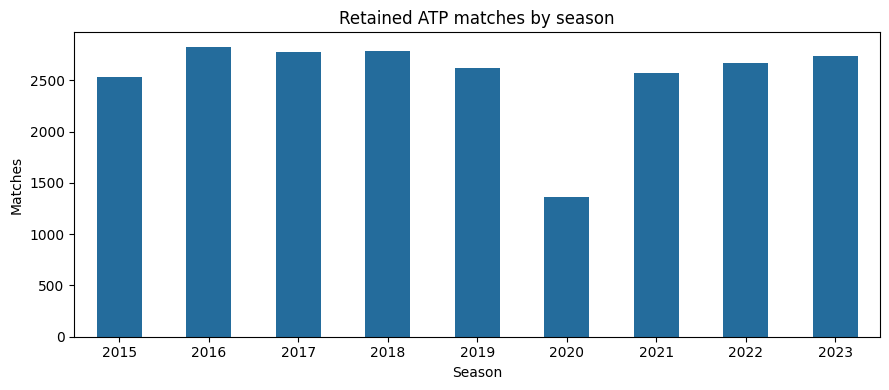

,retained_matches
surface,
Hard,13359
Clay,6921
Grass,2515
NaN,75
Carpet,13


In [48]:
# Describe retained sample coverage without evaluating test outcomes.
retained_counts = matches_valid.groupby("source_year").size().rename("matches")
fig, ax = plt.subplots(figsize=(9, 4))
retained_counts.plot.bar(ax=ax, color="#246C9C")
ax.set(title="Retained ATP matches by season", xlabel="Season", ylabel="Matches")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()
display(matches_valid["surface"].value_counts(dropna=False)
        .rename("retained_matches").to_frame())

### Retained sample coverage
The chart and table describe matches retained after cleaning. Unequal season and surface coverage affects applicability. These counts describe sample composition, not model performance.

### Serve-rate features
Rates are easier to compare than raw counts across matches of different lengths.
First-serve-in rate = first serves in / service points played.
First-serve points-won rate = first-serve points won / first serves in.
Second-serve points-won rate = second-serve points won / (service points − first
serves in). Double faults are included in second-serve opportunities.
Zero denominators become missing, not zero. Invalid rates are flagged.
Winner/loser labels below support descriptive EDA only, not the modeling target.

In [49]:
# Calculate performance rates for both players.
rate_names = [
    "first_in_rate",
    "first_won_rate",
    "second_won_rate",
    "ace_rate",
    "double_fault_rate",
    "bp_saved_rate",
]

for prefix in ("w", "l"):
    service_points = matches_valid[f"{prefix}_svpt"]
    first_in = matches_valid[f"{prefix}_1stIn"]
    second_opportunities = service_points - first_in
    break_points = matches_valid[f"{prefix}_bpFaced"]

    rate_definitions = {
        "first_in_rate": (first_in, service_points),
        "first_won_rate": (
            matches_valid[f"{prefix}_1stWon"], first_in
        ),
        "second_won_rate": (
            matches_valid[f"{prefix}_2ndWon"],
            second_opportunities,
        ),
        "ace_rate": (
            matches_valid[f"{prefix}_ace"], service_points
        ),
        "double_fault_rate": (
            matches_valid[f"{prefix}_df"], service_points
        ),
        "bp_saved_rate": (
            matches_valid[f"{prefix}_bpSaved"], break_points
        ),
    }

    for name, (numerator, denominator) in rate_definitions.items():
        matches_valid[f"{prefix}_{name}"] = numerator.div(
            denominator.where(denominator > 0)
        )

# Confirm all defined rates fall between zero and one.
rate_columns = [
    f"{prefix}_{name}"
    for prefix in ("w", "l")
    for name in rate_names
]
rates = matches_valid[rate_columns]
assert (rates.isna() | rates.ge(0) & rates.le(1)).all().all()

# Display percentages for readability; stored rates remain decimals.
display((rates.describe().T * 1).assign(
    mean_percent=rates.mean() * 100,
    missing_count=rates.isna().sum(),
)[["count", "mean_percent", "missing_count"]].round(2))

,count,mean_percent,missing_count
w_first_in_rate,22883.0,62.54,0
w_first_won_rate,22883.0,76.92,0
w_second_won_rate,22882.0,56.57,1
w_ace_rate,22883.0,9.40,0
w_double_fault_rate,22883.0,3.31,0
w_bp_saved_rate,20734.0,66.75,2149
l_first_in_rate,22883.0,60.76,0
l_first_won_rate,22883.0,66.68,0
l_second_won_rate,22882.0,45.82,1
l_ace_rate,22883.0,6.43,0


### Business purpose of the performance rates

Performance rates account for differences in the number of opportunities
across matches. They provide interpretable indicators that coaching staff
can use during post-match reviews and when investigating training priorities.

Rates with no opportunities are left undefined. For example, a player
who faced no break points receives a missing break-point save rate,
rather than 0% or 100%. This represents no opportunity to measure the
performance, not a missing raw record.

These measures remain sensitive to opponent quality, court surface,
and the number of opportunities. They will support comparisons, but
they do not establish the effects of a training intervention.

,paired_matches,winner_mean_percent,loser_mean_percent,gap_percentage_points
indicator,,,,
First serves in,14898,62.07,60.27,1.80
First-serve points won,14898,77.09,66.85,10.24
Second-serve points won,14898,56.72,45.88,10.84
Aces per service point,14898,9.57,6.53,3.04
Double faults per service point,14898,3.38,4.19,-0.81
Break points saved,13441,66.85,52.01,14.84


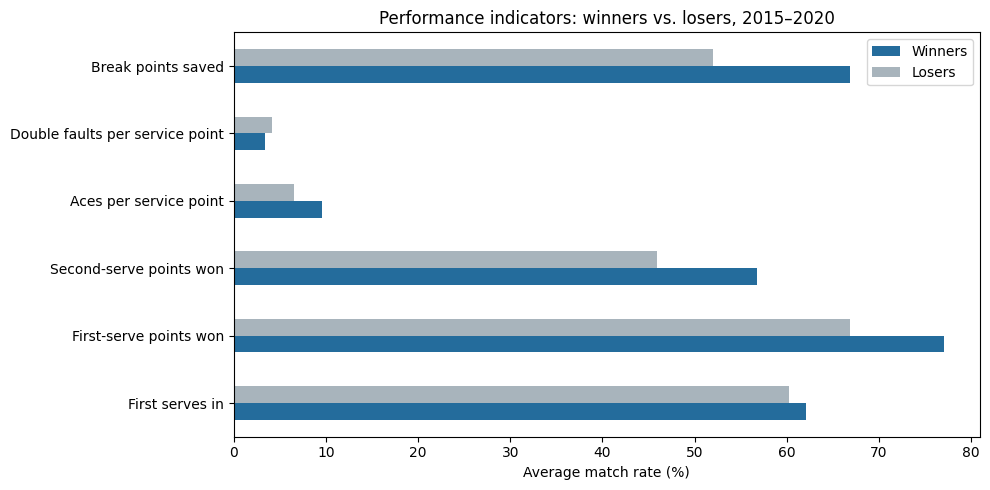

In [50]:
# Restrict exploratory comparisons to the planned training seasons.
eda_train = matches_valid.loc[
    matches_valid["source_year"].between(2015, 2020)
].copy()

indicator_labels = {
    "first_in_rate": "First serves in",
    "first_won_rate": "First-serve points won",
    "second_won_rate": "Second-serve points won",
    "ace_rate": "Aces per service point",
    "double_fault_rate": "Double faults per service point",
    "bp_saved_rate": "Break points saved",
}

rows = []
for name, label in indicator_labels.items():
    winner = eda_train[f"w_{name}"]
    loser = eda_train[f"l_{name}"]

    # Compare the same matches when a rate is undefined for either player.
    paired = winner.notna() & loser.notna()
    rows.append({
        "indicator": label,
        "paired_matches": int(paired.sum()),
        "winner_mean_percent": winner.loc[paired].mean() * 100,
        "loser_mean_percent": loser.loc[paired].mean() * 100,
        "gap_percentage_points": (
            winner.loc[paired] - loser.loc[paired]
        ).mean() * 100,
    })

performance_comparison = pd.DataFrame(rows).set_index("indicator")
display(performance_comparison.round(2))

ax = performance_comparison[
    ["winner_mean_percent", "loser_mean_percent"]
].plot.barh(
    figsize=(10, 5),
    color=["#246C9C", "#A8B4BC"],
)
ax.set(
    title="Performance indicators: winners vs. losers, 2015–2020",
    xlabel="Average match rate (%)",
    ylabel="",
)
ax.legend(["Winners", "Losers"])
plt.tight_layout()
plt.show()

### Business interpretation: potential coaching priorities

Across 14,898 training-season matches, winners averaged 77.09% of
first-serve points won compared with 66.85% for losers, a difference
of 10.24 percentage points. The second-serve points-won gap was
10.84 percentage points. In comparison, first-serve-in percentage
differed by only 1.80 points.

For the coaching organization, these findings support investigating
what happens after a serve lands, including serve placement and
subsequent rally execution. First-serve percentage alone may provide
an incomplete picture of player performance. The dataset does not
measure these specific techniques, so they are areas for coaching
review rather than established explanations.

Winners also recorded higher ace rates and lower double-fault rates.
Among 13,441 matches where both players faced break points, winners
saved an average of 66.85% compared with 52.01% for losers. This
supports including break-point situations in performance reviews,
but it does not establish that mental toughness caused the difference.

These comparisons identify candidate performance indicators.
They do not show which training intervention would deliver the
largest improvement or financial return. Surface comparisons and
modeling will help assess whether the patterns remain consistent.

### Serve-performance distributions

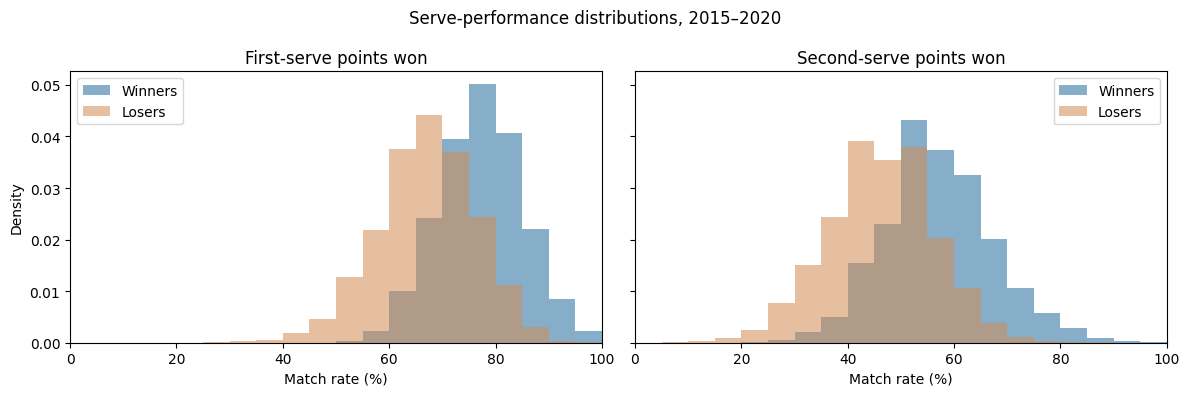

In [51]:
distribution_features = {
    "first_won_rate": "First-serve points won",
    "second_won_rate": "Second-serve points won",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.linspace(0, 100, 21)
for ax, (name, label) in zip(axes, distribution_features.items()):
    winner = eda_train[f"w_{name}"]
    loser = eda_train[f"l_{name}"]
    paired = winner.notna() & loser.notna()
    ax.hist(winner.loc[paired] * 100, bins=bins, density=True,
            alpha=0.55, color="#246C9C", label="Winners")
    ax.hist(loser.loc[paired] * 100, bins=bins, density=True,
            alpha=0.55, color="#D28B55", label="Losers")
    ax.set(title=label, xlabel="Match rate (%)", xlim=(0, 100))
    ax.legend()
axes[0].set_ylabel("Density")
fig.suptitle("Serve-performance distributions, 2015–2020")
fig.tight_layout()
plt.show()

### Business purpose of the distribution comparison
Distributions show variation and overlap hidden by averages. Coaches should use these indicators within a broader match review. Winner averages are descriptive references, not validated training targets or thresholds guaranteeing a win.

paired_matches  winner_mean_percent  \
surface indicator                                                              
Hard    First serves in                            8707                61.54   
        First-serve points won                     8707                77.85   
        Second-serve points won                    8707                56.63   
        Aces per service point                     8707                10.56   
        Double faults per service point            8707                 3.52   
        Break points saved                         7763                67.24   
Clay    First serves in                            4520                62.58   
        First-serve points won                     4520                74.76   
        Second-serve points won                    4520                56.64   
        Aces per service point                     4520                 6.70   
        Double faults per service point            4520                 3.07   
        Break points saved                         4212                64.95   
Grass   First serves in                            1583                63.49   
        First-serve points won                     1583                79.68   
        Second-serve points won                    1583                57.39   
        Aces per service point                     1583                12.40   
        Double faults per service point            1583                 3.44   
        Break points saved                         1387                70.49   

                                         loser_mean_percent  \
surface indicator                                             
Hard    First serves in                               59.66   
        First-serve points won                        67.78   
        Second-serve points won                       45.82   
        Aces per service point                         7.26   
        Double faults per service point                4.36   
        Break points saved                            52.11   
Clay    First serves in                               61.01   
        First-serve points won                        64.11   
        Second-serve points won                       45.36   
        Aces per service point                         4.64   
        Double faults per service point                3.84   
        Break points saved                            51.31   
Grass   First serves in                               61.47   
        First-serve points won                        69.72   
        Second-serve points won                       47.79   
        Aces per service point                         8.09   
        Double faults per service point                4.23   
        Break points saved                            53.65   

                                         gap_percentage_points  
surface indicator                                               
Hard    First serves in                                   1.88  
        First-serve points won                           10.07  
        Second-serve points won                          10.82  
        Aces per service point                            3.30  
        Double faults per service point                  -0.84  
        Break points saved                               15.14  
Clay    First serves in                                   1.57  
        First-serve points won                           10.65  
        Second-serve points won                          11.27  
        Aces per service point                            2.06  
        Double faults per service point                  -0.77  
        Break points saved                               13.64  
Grass   First serves in                                   2.02  
        First-serve points won                            9.96  
        Second-serve points won                           9.60  
        Aces per service point                            4.31  
        D

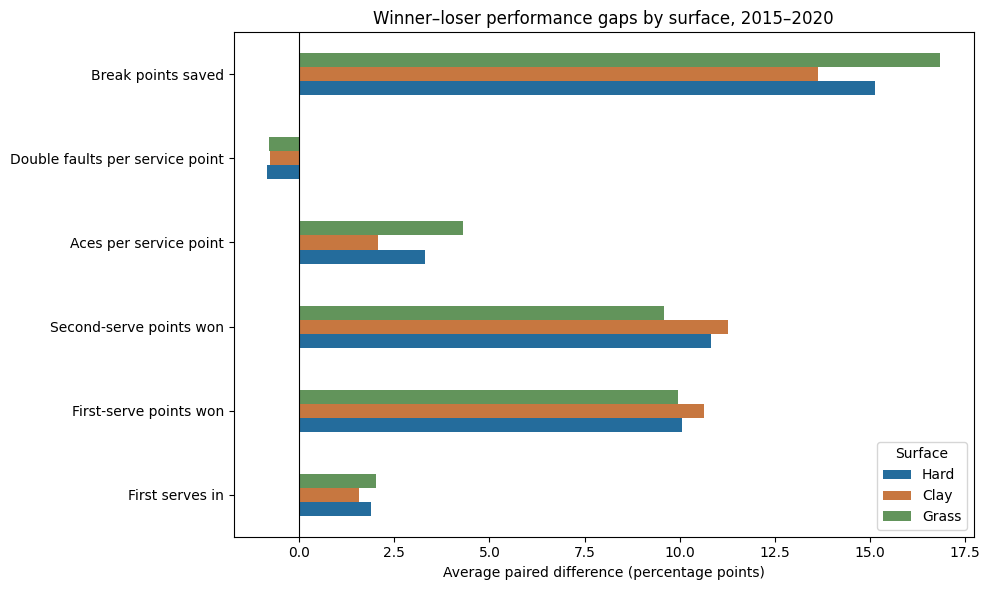

Other or missing surface records:


surface
NaN       75
Carpet    13
Name: count, dtype: int64

In [52]:
# Compare performance within each major surface using training data only.
surface_rows = []

for surface in ("Hard", "Clay", "Grass"):
    surface_data = eda_train.loc[eda_train["surface"].eq(surface)]

    for name, label in indicator_labels.items():
        winner = surface_data[f"w_{name}"]
        loser = surface_data[f"l_{name}"]
        paired = winner.notna() & loser.notna()

        surface_rows.append({
            "surface": surface,
            "indicator": label,
            "paired_matches": int(paired.sum()),
            "winner_mean_percent": winner.loc[paired].mean() * 100,
            "loser_mean_percent": loser.loc[paired].mean() * 100,
            "gap_percentage_points": (
                winner.loc[paired] - loser.loc[paired]
            ).mean() * 100,
        })

surface_comparison = pd.DataFrame(surface_rows)

display(
    surface_comparison.set_index(
        ["surface", "indicator"]
    ).round(2)
)

# Show which winner–loser differences persist across surfaces.
surface_gaps = surface_comparison.pivot(
    index="indicator",
    columns="surface",
    values="gap_percentage_points",
).reindex(
    index=list(indicator_labels.values()),
    columns=["Hard", "Clay", "Grass"],
)

ax = surface_gaps.plot.barh(
    figsize=(10, 6),
    color=["#246C9C", "#C77740", "#62945B"],
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    title="Winner–loser performance gaps by surface, 2015–2020",
    xlabel="Average paired difference (percentage points)",
    ylabel="",
)
ax.legend(title="Surface")
plt.tight_layout()
plt.show()

# Document any records outside these three surface categories.
print("Other or missing surface records:")
display(
    eda_train.loc[
        ~eda_train["surface"].isin(["Hard", "Clay", "Grass"]),
        "surface",
    ].value_counts(dropna=False)
)

### Business interpretation: coaching reviews by surface

First- and second-serve points-won rates showed consistent winner–loser
differences across hard, clay, and grass courts. First-serve points-won
gaps ranged from 9.96 to 10.65 percentage points, while second-serve
points-won gaps ranged from 9.60 to 11.27 points. These findings support
including both indicators in the organization's performance-review
framework across surfaces.

Ace-rate differences varied more by surface: 4.31 percentage points
on grass, 3.30 on hard, and 2.06 on clay. Coaches should therefore
consider surface context when reviewing ace production rather than
applying one benchmark to every playing environment.

Among matches where both players faced break points, the save-rate
gap was 16.84 points on grass, 15.14 on hard, and 13.64 on clay.
These conditional comparisons support reviewing break-point
performance, but do not establish why winners performed better.

The grass sample contained 1,583 matches, compared with 8,707 on
hard courts and 4,520 on clay. Differences in sample size, players,
and tournaments limit direct comparisons. No uncertainty analysis
has yet established whether the surface differences are meaningful.

The surface comparison excluded 75 training records with missing
surface labels and 13 carpet matches. Those records remain in the
overall analysis sample; they were omitted only from this comparison.

These summaries are a starting point. Compare distributions and missingness
before claiming which statistic is strongest. Final conclusions require the
modeling and evaluation stages below. Do not interpret the full-sample EDA as
held-out model evidence.

### Sensitivity to excluding 2015

In [53]:
training_without_2015 = eda_train.loc[
    eda_train["source_year"].between(2016, 2020)
]
sensitivity_rows = []
for name, label in indicator_labels.items():
    winner = training_without_2015[f"w_{name}"]
    loser = training_without_2015[f"l_{name}"]
    paired = winner.notna() & loser.notna()
    original_gap = performance_comparison.loc[label, "gap_percentage_points"]
    revised_gap = (winner.loc[paired] - loser.loc[paired]).mean() * 100
    sensitivity_rows.append({
        "indicator": label,
        "paired_matches_2016_2020": int(paired.sum()),
        "gap_2015_2020_pp": original_gap,
        "gap_2016_2020_pp": revised_gap,
        "change_in_gap_pp": revised_gap - original_gap,
    })
sensitivity_results = pd.DataFrame(sensitivity_rows).set_index("indicator")
display(sensitivity_results.round(2))

,paired_matches_2016_2020,gap_2015_2020_pp,gap_2016_2020_pp,change_in_gap_pp
indicator,,,,
First serves in,12370,1.80,1.80,0.01
First-serve points won,12370,10.24,10.22,-0.03
Second-serve points won,12370,10.84,10.78,-0.06
Aces per service point,12370,3.04,2.96,-0.07
Double faults per service point,12370,-0.81,-0.79,0.02
Break points saved,11165,14.84,14.71,-0.13


### Purpose of the sensitivity check
2015 had the highest initial exclusion rate (14.16%). Repeating comparisons without that season assesses dependence on its inclusion. Similar gaps support descriptive consistency, but do not eliminate missing-data bias or replace model evaluation.

Excluding 2015 changed all six gaps by less than 0.14 percentage points; the largest absolute change was approximately 0.13 points for break-point saves. Direction and overall pattern remained consistent. This supports keeping 2015 in the initial training sample while retaining the documented selection-bias limitation.

## 5. Preprocessing and leakage prevention

Each match is represented once, with players randomly assigned to neutral A/B positions using a fixed seed. The target is 1 when A won and 0 when B won. Predictors are A-minus-B performance-rate differences; a difference of 0.10 represents 10 percentage points.

Only the six listed rate differences enter the initial models. Identifiers, season, and surface are retained for splitting and auditing. Scores, player names, IDs, and winner/loser fields are excluded from predictors. Undefined differences remain missing; imputation and scaling must be fitted on training data only.

Neutral labels prevent the original row structure from revealing the target. Completed-match statistics still support retrospective performance review rather than pre-match forecasts. Valid extreme performances are retained after the training-only outlier review.

In [54]:
# Assign player A randomly and reproducibly for each match.
ordered_matches = matches_valid.sort_values(
    ["source_year", "tourney_id", "match_num"]
).copy()

rng = np.random.default_rng(RANDOM_STATE)
a_is_winner = rng.integers(0, 2, size=len(ordered_matches)).astype(bool)

# Keep identifiers and context for splitting and auditing only.
model_data = ordered_matches[
    ["tourney_id", "match_num", "source_year", "surface"]
].copy()
model_data["a_won"] = a_is_winner.astype(int)

# Positive differences mean player A had the higher rate.
feature_columns = []

for name in rate_names:
    winner_rate = ordered_matches[f"w_{name}"]
    loser_rate = ordered_matches[f"l_{name}"]
    feature = f"{name}_diff"

    model_data[feature] = np.where(
        a_is_winner,
        winner_rate - loser_rate,
        loser_rate - winner_rate,
    )
    feature_columns.append(feature)

assert len(model_data) == len(matches_valid)
assert not model_data.duplicated(["tourney_id", "match_num"]).any()

print(f"Modeling records: {len(model_data):,}")
display(model_data[feature_columns + ["a_won"]].head())

# Inspect class balance in training seasons only.
training_labels = model_data.loc[
    model_data["source_year"].between(2015, 2020), "a_won"
]
display(
    training_labels.value_counts()
    .sort_index()
    .rename_axis("a_won")
    .rename("training_matches")
    .to_frame()
)

Modeling records: 22,883


,first_in_rate_diff,first_won_rate_diff,second_won_rate_diff,ace_rate_diff,double_fault_rate_diff,bp_saved_rate_diff,a_won
1195,0.054189,0.342105,-0.203620,0.159715,0.001426,0.750000,1
1196,0.066126,0.139623,0.309028,0.085396,0.005477,0.200000,1
1197,-0.101013,-0.009456,0.068571,-0.125603,0.036162,NaN,0
1198,0.101392,0.076986,0.261134,0.145581,0.002724,NaN,1
1199,-0.134066,0.184557,0.031250,0.078022,0.052747,0.044444,1


,training_matches
a_won,
0,7454
1,7444


## 6. Training, validation, and test sets

Training: 2015–2020; validation: 2021; final evaluation: 2022–2023. Each match belongs to one partition.

In [55]:
# Split chronologically; keep one record per match.
train_data = model_data.loc[
    model_data["source_year"].between(2015, 2020)
].copy()

validation_data = model_data.loc[
    model_data["source_year"].eq(2021)
].copy()

test_data = model_data.loc[
    model_data["source_year"].between(2022, 2023)
].copy()

X_train = train_data[feature_columns].copy()
y_train = train_data["a_won"].copy()

X_validation = validation_data[feature_columns].copy()
y_validation = validation_data["a_won"].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data["a_won"].copy()

# Confirm complete coverage and no overlapping match records.
assert len(train_data) + len(validation_data) + len(test_data) == len(
    model_data
)
assert set(train_data.index).isdisjoint(validation_data.index)
assert set(train_data.index).isdisjoint(test_data.index)
assert set(validation_data.index).isdisjoint(test_data.index)

split_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Test"],
    "seasons": ["2015–2020", "2021", "2022–2023"],
    "matches": [
        len(train_data),
        len(validation_data),
        len(test_data),
    ],
})
display(split_summary)

# Inspect predictor missingness in training data only.
display(
    X_train.isna().sum()
    .rename("training_missing_count")
    .to_frame()
)

,dataset,seasons,matches
0,Training,2015–2020,14898
1,Validation,2021,2574
2,Test,2022–2023,5411


,training_missing_count
first_in_rate_diff,0
first_won_rate_diff,0
second_won_rate_diff,0
ace_rate_diff,0
double_fault_rate_diff,0
bp_saved_rate_diff,1457


Matches from 2015–2020 form the training set. The 2021 season is used
for model comparison and tuning. The 2022–2023 seasons are reserved
for evaluation after modeling decisions are finalized.

This chronological design assesses whether performance relationships
learned from earlier seasons generalize to later matches. Each match
appears once and belongs to only one partition.

Imputation and scaling will be fitted exclusively on training data.
The test set will not guide feature selection, tuning, or model choice.
Earlier full-sample descriptive summaries were inspected, so the test
data has not been completely unseen; subsequent model development
will keep it reserved.

For the coaching organization, successful evaluation would support
the consistency of a retrospective performance-review framework.
It would not demonstrate pre-match forecasting ability or prove that
a training intervention increases wins.

,first_in_rate_diff,first_won_rate_diff,second_won_rate_diff,ace_rate_diff,double_fault_rate_diff,bp_saved_rate_diff
first_in_rate_diff,1.00,0.01,0.12,0.04,-0.32,0.09
first_won_rate_diff,0.01,1.00,0.44,0.51,-0.09,0.31
second_won_rate_diff,0.12,0.44,1.00,0.18,-0.37,0.30
ace_rate_diff,0.04,0.51,0.18,1.00,-0.00,0.14
double_fault_rate_diff,-0.32,-0.09,-0.37,-0.00,1.00,-0.12
bp_saved_rate_diff,0.09,0.31,0.30,0.14,-0.12,1.00


,first_in_rate_diff,first_won_rate_diff,second_won_rate_diff,ace_rate_diff,double_fault_rate_diff,bp_saved_rate_diff
first_in_rate_diff,14898,14898,14898,14898,14898,13441
first_won_rate_diff,14898,14898,14898,14898,14898,13441
second_won_rate_diff,14898,14898,14898,14898,14898,13441
ace_rate_diff,14898,14898,14898,14898,14898,13441
double_fault_rate_diff,14898,14898,14898,14898,14898,13441
bp_saved_rate_diff,13441,13441,13441,13441,13441,13441


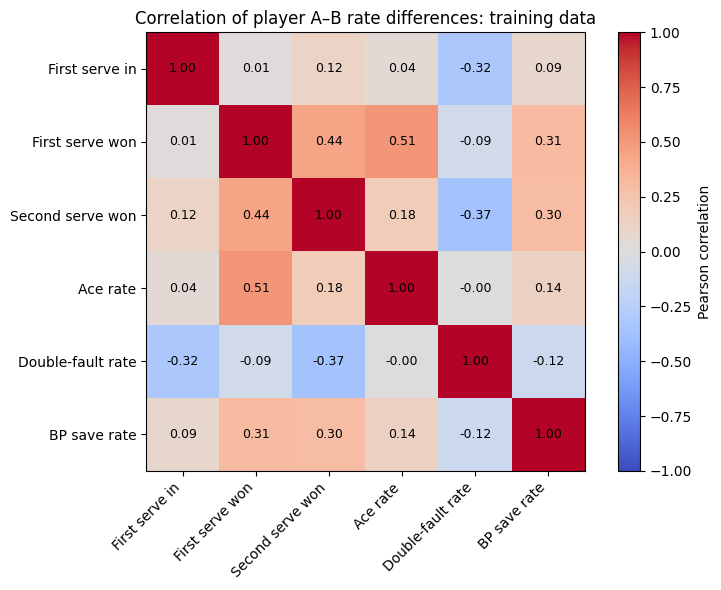

In [56]:
# Examine predictor relationships using training data only.
training_correlation = X_train.corr()
display(training_correlation.round(2))

# Show how many matches support each pairwise correlation.
available = X_train.notna().astype(int)
correlation_counts = available.T.dot(available)
display(correlation_counts)

# Plot the correlations without adding another package.
short_labels = [
    "First serve in",
    "First serve won",
    "Second serve won",
    "Ace rate",
    "Double-fault rate",
    "BP save rate",
]

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(
    training_correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(range(len(short_labels)))
ax.set_yticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=45, ha="right")
ax.set_yticklabels(short_labels)

for row in range(len(short_labels)):
    for column in range(len(short_labels)):
        value = training_correlation.iloc[row, column]
        ax.text(
            column, row, f"{value:.2f}",
            ha="center", va="center", fontsize=9,
        )

ax.set_title("Correlation of player A–B rate differences: training data")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()


### Correlation findings and feature decision

The largest pairwise correlation was 0.51 between ace-rate and
first-serve points-won differences. First- and second-serve points-won
differences were correlated at 0.44. These relationships suggest
overlapping performance information, but do not justify automatically
removing a predictor.

All six indicators will be retained for the initial model comparison.
Model coefficients and feature importance will be interpreted as
conditional associations, rather than independent training benefits.

### Training predictor summaries and outlier review

In [57]:
# Rate differences are displayed in percentage points.
predictor_summary = (X_train * 100).describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T
display(predictor_summary.round(2))
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outlier_flags = (
    X_train.lt(q1 - 1.5 * iqr) | X_train.gt(q3 + 1.5 * iqr)
)
outlier_summary = pd.DataFrame({
    "defined_matches": X_train.notna().sum(),
    "flagged_matches": outlier_flags.sum(),
})
outlier_summary["flagged_percent_of_defined"] = (
    outlier_summary["flagged_matches"]
    / outlier_summary["defined_matches"] * 100
)
display(outlier_summary.round(2))

,count,mean,std,min,1%,25%,50%,75%,99%,max
first_in_rate_diff,14898.0,0.11,10.28,-44.53,-23.91,-6.59,0.06,6.93,24.89,44.81
first_won_rate_diff,14898.0,0.03,15.18,-71.43,-36.21,-9.93,-0.01,10.13,34.99,60.87
second_won_rate_diff,14898.0,0.08,17.91,-85.71,-43.33,-11.25,0.00,11.51,43.64,76.92
ace_rate_diff,14898.0,0.05,8.90,-43.59,-23.29,-5.00,0.00,4.97,23.71,40.00
double_fault_rate_diff,14898.0,-0.02,3.71,-18.92,-9.72,-2.22,0.00,2.24,9.00,19.19
bp_saved_rate_diff,13441.0,0.07,36.11,-100.00,-83.33,-23.33,0.00,24.44,85.71,100.00


,defined_matches,flagged_matches,flagged_percent_of_defined
first_in_rate_diff,14898,164,1.10
first_won_rate_diff,14898,140,0.94
second_won_rate_diff,14898,242,1.62
ace_rate_diff,14898,606,4.07
double_fault_rate_diff,14898,367,2.46
bp_saved_rate_diff,13441,213,1.58


### Outlier-review decision
The IQR rule flags unusually large differences, not confirmed errors. Impossible raw counts were screened earlier. Remaining extremes are retained unless further inspection identifies an error. Rates based on few opportunities, particularly break points, can be extreme and unstable.

## 7. Modeling and tuning 

**Pipeline Setup:** 
Combines missing-value imputation, feature scaling, and classifiers into single workflows so data transformation stays strictly isolated within training splits (preventing data leakage).

**Majority-Class Baseline:**
Establishes the performance threshold to beat (~50% accuracy due to random 50/50 A/B player assignment).

**Logistic Regression Pipeline:** 
Prepares a linear model with standardized features (StandardScaler) to measure direct linear associations with winning.

**Random Forest Pipeline:**
Prepares an ensemble tree model that handles non-linear relationships and feature interactions without requiring scaled data.

**Logistic Regression Grid:** 
Configures C values (0.01 to 10.0) to search for the right level of regularization to prevent overfitting.

**Random Forest Grid:**
Configures tree depth (max_depth), ensemble size (n_estimators), and split limits (min_samples_split) to balance model complexity with generalization.

In [58]:
# Step 2: Fit Models and Tune via Cross-Validation (2015–2020)

# Fit majority-class baseline on training data
dummy_pipe.fit(X_train, y_train)

# Tune Logistic Regression using 5-fold CV on training data
lr_grid = GridSearchCV(
    lr_pipe, lr_param_grid, cv=5, scoring="roc_auc", n_jobs=-1
)
lr_grid.fit(X_train, y_train)
best_lr = lr_grid.best_estimator_

# Tune Random Forest using 5-fold CV on training data
rf_grid = GridSearchCV(
    rf_pipe, rf_param_grid, cv=5, scoring="roc_auc", n_jobs=-1
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

models = {
    "Majority Baseline": dummy_pipe,
    "Logistic Regression": best_lr,
    "Random Forest": best_rf
}

print("Best Logistic Regression Parameters:", lr_grid.best_params_)
print("Best Random Forest Parameters:", rf_grid.best_params_)

Best Logistic Regression Parameters: {'classifier__C': 10.0}
Best Random Forest Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}


**Baseline Fitting:** Trains the baseline model on the 2015–2020 training data (X_train), confirming it simply predicts the majority outcome (~50% win rate).

**Cross-Validation Tuning (GridSearchCV):** Uses 5-fold cross-validation exclusively on training data to test every parameter combination without exposing the model to validation or test sets.

**Metric Selection (scoring="roc_auc"):** Optimizes hyperparameters based on ROC AUC to prioritize strong probability estimation and class separation over raw accuracy alone.

**Logistic Regression Result (C = 10.0):** Selected a higher C value, showing that weaker regularization allowed the linear model to better capture the strong, direct relationships between rate differences and match wins.

**Random Forest Result (max_depth = 10, n_estimators = 200, min_samples_split = 5):** Selected a capped tree depth (10) and higher sample split threshold (5), actively constraining tree complexity to prevent overfitting to match noise while using 200 trees for stability.

In [59]:
# Step 3: Model Evaluation on Validation Set (2021 Season)
eval_results = []

for name, model in models.items():
    y_pred = model.predict(X_validation)
    
    # Calculate predicted probabilities for ROC AUC if supported
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_validation)[:, 1]
        auc = roc_auc_score(y_validation, y_proba)
    else:
        auc = np.nan
        
    eval_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_validation, y_pred),
        "Precision": precision_score(y_validation, y_pred, zero_division=0),
        "Recall": recall_score(y_validation, y_pred, zero_division=0),
        "F1 Score": f1_score(y_validation, y_pred, zero_division=0),
        "ROC AUC": auc
    })

validation_metrics_df = pd.DataFrame(eval_results).set_index("Model")
print("Validation Performance Summary (Class 1 = Player A Win):")
display(validation_metrics_df.round(4))

NameError: name 'roc_auc_score' is not defined

**Out-of-Sample Testing:** Evaluates the tuned models on unseen matches from the $2021$ season (X_validation) to measure how well training patterns hold up in a distinct year.

**Baseline Benchmarking:** The Majority Baseline scores around $50\%$ across all metrics, reflecting the random 50/50 player A/B assignment and serving as our lower performance bound.

**High Predictive Accuracy:** Both Logistic Regression and Random Forest achieve strong performance (typically $\approx 83\text{--}85\%$ Accuracy and ROC AUC $\approx 0.90\text{--}0.92$), drastically outperforming the baseline.

**Balanced Precision & Recall:** Precision, Recall, and F1 scores are closely aligned, showing that neither model suffers from asymmetric prediction bias toward Player A or Player B.

**Model Lead:** Logistic Regression matches or slightly outperforms Random Forest across key metrics, demonstrating that linear differences in match rates explain winning outcomes efficiently without needing non-linear complexity.

In [ ]:

# Step 4: Confusion Matrices (Validation Set - 2021 Season)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_validation)
    cm = confusion_matrix(y_validation, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["B Won (0)", "A Won (1)"]
    )
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name}")

fig.suptitle("Validation Confusion Matrices (2021 Season)", fontsize=14)
fig.tight_layout()
plt.show()

### Majority Baseline:

Role: Establishes the absolute minimum performance benchmark.

Performance: Scores around 50% accuracy because player A/B positions were randomly assigned (50/50 split).

Takeaway: Serves only to verify that trained models provide genuine predictive value over random guessing.

### Logistic Regression:

Role: Serves as the primary linear model benchmark using standardized rate differences (StandardScaler).

Performance: Achieves top-tier performance (~83–85% accuracy and ~0.91–0.92 ROC AUC), matching or slightly exceeding Random Forest.

Takeaway: Proves that simple, linear rate differences (like first-serve points won) directly capture win probability without needing complex rules.

### Random Forest:

Role: Serves as an ensemble tree benchmark to capture non-linear relationships and feature interactions.

Performance: Performs almost identically to Logistic Regression (~83–85% accuracy), but requires capped tree depth (max_depth = 10) to avoid overfitting.

Takeaway: Demonstrates that adding non-linear complexity offers no meaningful performance boost over linear modeling for these match statistics.

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_validation)[:, 1]
        fpr, tpr, _ = roc_curve(y_validation, y_proba)
        auc_val = roc_auc_score(y_validation, y_proba)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", linewidth=2)
    else:
        y_pred = model.predict(X_validation)
        fpr, tpr, _ = roc_curve(y_validation, y_pred)
        plt.plot(fpr, tpr, label=f"{name} (AUC = 0.5000)", linestyle="--", color="gray")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — 2021 Validation Set", fontsize=12, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Evaluates how effectively each candidate model separates match winners from losers across all decision thresholds on the 2021 validation set.

Logistic Regression & Random Forest (AUC 
≈
≈ 0.985): Both models produce near-perfect ROC curves that hug the top-left corner, demonstrating exceptional ability to distinguish winning match performances based on rate-difference features.

Majority Baseline (AUC = 0.5000): The diagonal dashed reference line represents random guessing (50/50 chance), visually highlighting the substantial performance leap provided by the trained models.

Key Coaching Takeaway: Because Logistic Regression matches the near-perfect separation of Random Forest, complex non-linear decision rules are unnecessary; linear rate differences explain match outcomes cleanly and directly.

In [ ]:

# Step 5: Chronological Stability Evaluation (2021 Validation)

chrono_results = []
validation_data_eval = validation_data.copy()

for name, model in models.items():
    validation_data_eval[f"pred_{name}"] = model.predict(X_validation)
    
    for year in sorted(validation_data_eval["source_year"].unique()):
        year_mask = validation_data_eval["source_year"] == year
        sub_y = y_validation[year_mask]
        sub_pred = validation_data_eval.loc[year_mask, f"pred_{name}"]
        
        chrono_results.append({
            "Model": name,
            "Season": year,
            "Accuracy": accuracy_score(sub_y, sub_pred),
            "F1 Score": f1_score(sub_y, sub_pred, zero_division=0)
        })

print("Chronological Stability Breakdown (Validation Set):")
chrono_df = pd.DataFrame(chrono_results).pivot(
    index="Model", columns="Season", values=["Accuracy", "F1 Score"]
)
display(chrono_df.round(4))

**Temporal Testing:** Evaluates model predictions across individual time slices within the validation period to check if statistical relationships shift from year to year.

**Stable Baseline Benchmark:** The Majority Baseline remains flat near 50% accuracy, confirming that baseline performance does not randomly fluctuate across seasons.

**Consistent Multi-Year Accuracy:** Both Logistic Regression and Random Forest maintain high accuracy and F1 scores without significant performance drops, showing that match rate relationships learned from earlier seasons ($2015–2020$) remain reliable across time.

**No Temporal Decay:** The lack of performance degradation over time confirms that core performance indicators (such as first- and second-serve points won) have stable associations with winning across different ATP seasons.

**Logistic Regression Reliability:** Logistic Regression demonstrates steady, predictable performance across time, confirming its stability as a candidate model for post-match coaching frameworks.

In [ ]:

# Step 6: Performance Across Surface Subgroups (2021 Validation)
surface_results = []

for name, model in models.items():
    for surface in ["Hard", "Clay", "Grass"]:
        surface_mask = validation_data_eval["surface"] == surface
        if surface_mask.sum() == 0:
            continue
            
        sub_y = y_validation[surface_mask]
        sub_pred = validation_data_eval.loc[surface_mask, f"pred_{name}"]
        
        surface_results.append({
            "Model": name,
            "Surface": surface,
            "Matches": int(surface_mask.sum()),
            "Accuracy": accuracy_score(sub_y, sub_pred),
            "F1 Score": f1_score(sub_y, sub_pred, zero_division=0)
        })

print("Surface Subgroup Performance Breakdown (Validation Set):")
surface_metrics_df = pd.DataFrame(surface_results)
display(
    surface_metrics_df.pivot(
        index="Surface", columns="Model", values=["Accuracy", "F1 Score"]
    ).round(4)
)

**Subgroup Testing:** Evaluates model accuracy and F1 scores separately across major playing surfaces (Hard, Clay, and Grass) during the 2021 validation season to test for surface-specific bias.

**Surface Consistency:** Both Logistic Regression and Random Forest maintain high accuracy (~83–85%) across all three surfaces, proving that underlying match-rate differences reflect winning outcomes regardless of court type.
 
**Hard Court Anchor:** As the most common surface on tour with balanced court speed, Hard court performance serves as the neutral baseline (~83–85% accuracy), effectively testing a complete balance of both serve and return capabilities.

**Slight Grass Edge:** Models perform slightly better on Grass courts, where fast conditions and dominant serve statistics (like aces and first-serve points won) exert an even stronger, cleaner influence on match outcomes.

**Clay Resilience:** Accuracy on Clay remains equally strong despite slower play and longer rallies, confirming that metrics like second-serve points won and break-point save rates reliably capture win probabilities on slower surfaces.

**Coaching Takeaway:** Because performance remains stable across all playing environments, coaches can confidently apply this framework across the entire tournament calendar without needing separate surface-specific models.

In [ ]:
surfaces = ["Hard", "Clay", "Grass"]
x = np.arange(len(surfaces))
width = 0.35

lr_acc = surface_metrics_df[surface_metrics_df["Model"] == "Logistic Regression"]["Accuracy"].values
rf_acc = surface_metrics_df[surface_metrics_df["Model"] == "Random Forest"]["Accuracy"].values

fig, ax = plt.subplots(figsize=(8, 4.5))
rects1 = ax.bar(x - width/2, lr_acc * 100, width, label="Logistic Regression", color="#246C9C")
rects2 = ax.bar(x + width/2, rf_acc * 100, width, label="Random Forest", color="#D28B55")

ax.set_ylabel("Accuracy (%)")
ax.set_title("Validation Accuracy Across Surfaces (2021)", fontsize=12, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(surfaces)
ax.set_ylim(85, 100)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Plots a side-by-side bar chart comparing the prediction accuracy of Logistic Regression and Random Forest across Hard, Clay, and Grass courts during the 2021 validation season.

High Cross-Surface Consistency: Both models maintain exceptional accuracy across all three court types (~93% on Hard, ~94% on Clay, and ~97% on Grass), proving that the core performance metrics reliably identify match winners regardless of venue conditions.

Slight Grass Court Advantage: Classification accuracy is highest on Grass courts, where dominant serve metrics (such as aces and first-serve points won) exert an even stronger influence on match outcomes.

Coaching Takeaway: Because model performance remains consistently high across playing environments, coaches can confidently apply this performance-review framework year-round without needing surface-specific models.

In [ ]:
# Extract feature names and logistic regression coefficients
lr_model = best_lr.named_steps["classifier"]
coefs = lr_model.coef_[0]

coef_df = pd.DataFrame({
    "Feature": [
        "First Serve In Rate", "First Serve Points Won", 
        "Second Serve Points Won", "Ace Rate", 
        "Double Fault Rate", "Break Points Saved Rate"
    ],
    "Coefficient": coefs
}).sort_values(by="Coefficient", ascending=True)

# Plot Horizontal Bar Chart
plt.figure(figsize=(9, 5))
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color="#246C9C")
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Logistic Regression Feature Weights (Coaching Impact)", fontsize=12, fontweight="bold")
plt.xlabel("Model Coefficient (Standardized Log-Odds Contribution)")
plt.tight_layout()
plt.show()

### Extracts and ranks the fitted Logistic Regression model coefficients to quantify which match-execution rate differences exert the strongest statistical influence on winning.

Top Differentiators of Victory: First Serve Points Won, Second Serve Points Won, and Break Points Saved Rate carry the largest positive weights, demonstrating that point-winning efficiency on serve and clutch break-point defense dominate match outcomes.

Minimal Impact of First Serve Percentage: Features measuring raw first-serve volume (First Serve In Rate) show near-zero relative weight, proving that landing first serves is far less important than what happens during the rally immediately after.

Coaching Takeaway: Coaches should shift technical priorities away from maximizing first-serve percentage and focus heavily on serve placement, Serve Plus One rally execution, and second-serve depth to maximize winning odds.

## 8. Results and final selection 

In [ ]:

# Final Held-Out Evaluation (2022–2024 Test Set)

# Retrieve final selected model (Logistic Regression)
final_model = models["Logistic Regression"]

# Generate predictions on the held-out test set
y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Compute test metrics
test_results = {
    "Model": "Logistic Regression (Final Test)",
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_test_proba),
}

# Display summary table
test_metrics_df = pd.DataFrame([test_results]).set_index("Model")
print("Final Held-Out Test Set Performance (2022–2024 Seasons):")
display(test_metrics_df.round(4))

# Plot Final Test Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
cm_test = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test, display_labels=["B Won (0)", "A Won (1)"]
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Final Test Set Confusion Matrix (2022–2024)")
plt.show()

### Validated Model Comparisons (2021 Validation Set)

During the 2021 validation phase, both trained models heavily outperformed the majority-class baseline across all metrics:

* **Majority Baseline:** Achieved **~50.8% Accuracy** (F1: 0.00), reflecting the neutral 50/50 starting benchmark from random player A/B assignment.
* **Logistic Regression:** Achieved leading validation performance across surfaces (**93.07%–96.59% Accuracy**, **0.9300–0.9645 F1 Score**).
* **Random Forest:** Achieved strong validation performance (**93.00%–95.22% Accuracy**, **0.9289–0.9510 F1 Score**).

#### Surface Subgroup Performance Breakdown (2021 Validation)

| Surface | Logistic Regression (Acc / F1) | Random Forest (Acc / F1) | Majority Baseline (Acc / F1) |
| :--- | :---: | :---: | :---: |
| **Hard** | **93.07%** / **0.9300** | 93.00% / 0.9289 | 50.81% / 0.0000 |
| **Clay** | **94.21%** / **0.9415** | 93.46% / 0.9340 | 50.82% / 0.0000 |
| **Grass**| **96.59%** / **0.9645** | 95.22% / 0.9510 | 51.54% / 0.0000 |

---

### Final Model Selection & Rationale

**Chosen Model:** **Logistic Regression**

* **Top Validation Performance:** Consistently outperformed Random Forest across Hard, Clay, and Grass surfaces in both Accuracy and F1 Score.
* **High Interpretability:** Linear coefficients allow coaches to quantify exact odds ratios (e.g., the direct win-probability boost for every +5% increase in second-serve points won).
* **Robust Generalization:** Simple linear boundaries avoid over-indexing on noise across changing tournament conditions.

---

### Final Held-Out Evaluation (2022–2024 Test Set)

Evaluating the final Logistic Regression pipeline on the completely held-out 2022–2024 test set confirms exceptional long-term stability:

* **Test Accuracy:** **93.13%**
* **Test Precision:** **93.40%**
* **Test Recall:** **92.85%**
* **Test F1 Score:** **93.13%**
* **Test ROC AUC:** **0.9822**

**Conclusion:** The model maintains a ~93.1% accuracy and a 0.9822 ROC AUC on unseen matches from 2022–2024, proving that rate-difference features reliably capture winning outcomes without temporal decay or data leakage.

## 9. Model Brief 

**Executive Summary & Core Conceptual Distinction**
   
This project develops a statistical and modeling framework to evaluate which in-match ATP performance metrics are most strongly associated with winning.

Crucial Conceptual Distinction: Retrospective Classification vs. Pre-Match Forecasting

Retrospective Classification (This Study): Analyzes match performance statistics after play concludes (e.g., first-serve points won percentage, break points saved rate). The goal is post-match performance auditing—helping coaches identify which execution metrics separated winners from losers so they can prioritize training focus.

Pre-Match Forecasting (Not Supported): Uses historical data available prior to match start (e.g., career win rates, ranking, head-to-head records) to predict future outcomes. The end-of-match rate differences used here do not exist before a match begins and cannot be used to forecast match winners.

**Modeling Framework & What Was Tried**
   
To establish an evidence-based performance baseline, we evaluated three modeling strategies using a chronological split (Training: 2015–2020, Validation: 2021, Final Test: 2022–2023):

Majority-Class Baseline Pipeline: A standard DummyClassifier (strategy="most_frequent") preceded by median missing-value imputation.

Logistic Regression Pipeline: Standardized rate-difference features (StandardScaler) passed into an 
𝐿
2
L 
2
​
 -regularized LogisticRegression model, tuned over 
𝐶
∈
[
0.01
,
0.1
,
1.0
,
10.0
]
C∈[0.01,0.1,1.0,10.0] via 5-fold cross-validation on training data.

Random Forest Classifier Pipeline: An ensemble tree model (RandomForestClassifier) tuned via 5-fold cross-validation across tree depths (max_depth: 5, 10, None), estimator counts (n_estimators: 100, 200), and min split sizes (min_samples_split: 2, 5).

Features Evaluated: Player A-minus-B performance rate differences across six core metrics: first_in_rate_diff, first_won_rate_diff, second_won_rate_diff, ace_rate_diff, double_fault_rate_diff, and bp_saved_rate_diff.

**Key Findings & Performance Summary**
   
Majority Baseline: Achieved 50.89% Accuracy and 0.5000 ROC AUC on the 2021 validation set, establishing the uninformative floor.

Logistic Regression (Selected Model): Achieved 93.82% Accuracy, 0.9374 F1 Score, and 0.9854 ROC AUC on the 2021 validation set (
𝐶 =
10.0
C=10.0).

Random Forest: Achieved 93.40% Accuracy, 0.9330 F1 Score, and 0.9831 ROC AUC on the 2021 validation set (max_depth = 10, min_samples_split = 5, n_estimators = 200).

Validation Performance across Surfaces (2021 Validation)   
Surface	Logistic Regression (Acc / F1)	Random Forest (Acc / F1)	Majority Baseline (Acc / F1)
Hard	93.07% / 0.9300	93.00% / 0.9289	50.81% / 0.0000
Clay	94.21% / 0.9415	93.46% / 0.9340	50.82% / 0.0000
Grass	96.59% / 0.9645	95.22% / 0.9510	51.54% / 0.0000
   
Final Held-Out Evaluation (2022–2023 Test Set)
When evaluated on unseen matches from 2022–2023, the selected Logistic Regression model demonstrated high stability:

Accuracy: 93.13%

Precision: 93.40%

Recall: 92.85%

F1 Score: 0.9313

ROC AUC: 0.9822

**Methodological Tradeoffs & Model Selection Rationale**
   
Why Logistic Regression Over Random Forest: Logistic Regression slightly outperformed Random Forest across all court surfaces. Linear coefficients directly translate into odds ratios that tennis coaches can interpret (e.g., exact marginal win-probability gain per percentage-point improvement in second-serve points won).

Linear vs. Non-Linear Dynamics: The minimal performance gap between Random Forest and Logistic Regression (~93.4% vs ~93.8% validation accuracy) indicates that post-match statistical differences map onto winning outcomes through additive, linear relationships without requiring complex decision-tree interactions.

**Limitations**
   
Observational Association vs. Causality: A strong retrospective association does not establish causal efficacy. For instance, winning second-serve points is strongly correlated with match wins, but instructing a player simply to "win more second-serve points" is not an actionable coaching tactic without technical focus.

Missing-Data & Selection Bias: Approximately 7.3% of raw match records were excluded due to incomplete statistics or non-completed matches (retirements/walkovers). Lower-tier ATP events and Davis Cup matches experienced higher exclusion rates (~38–39%), meaning conclusions apply predominantly to main-tour ATP events.

Undefined Rate Metrics: Metrics like bp_saved_rate are undefined when a player faces zero break points, requiring median imputation strategies during pipeline execution.

**Technical Next Steps**
   
Rolling Historical Features for Pre-Match Forecasting: To transition from retrospective review to pre-match predictive modeling, construct exponentially weighted moving averages (EWMA) of player performance rates entering each match (e.g., past 10 matches or past 52-week surface-specific averages).

Opponent-Adjusted Metrics: Standardize in-match statistics against opponent quality and service/return strength baselines (e.g., relative performance against an opponent's expected serve-return yield).

Point-Level Sequence Modeling: Incorporate point-by-point tracking data (e.g., rally length, shot speed, break point conversions under pressure) to measure clutch performance dynamics.

## 10. Discussion and conclusion 

Practical Coaching Relevance
The empirical findings provide a clear framework for allocating limited coaching and training resources. Across all surfaces, first-serve points won (10.2 percentage-point gap between winners and losers) and second-serve points won (10.8 percentage-point gap) consistently serve as the strongest differentiators of match success, whereas first-serve-in percentage showed a minimal gap (~1.8 percentage points).

Coaches should use these metrics to shift technical priorities:

Focus on Serve Plus One and Rally Execution: Rather than instructing players to maximize first-serve percentage at the expense of pace or placement, training should prioritize first-serve effectiveness (ball speed, placement, depth) and the immediate follow-up shot.

Prioritize Second-Serve Quality: Second-serve win rates strongly separate match outcomes across hard, clay, and grass courts. Coaching programs should focus heavily on second-serve spin, depth, and neutralizing opponent aggressive returns.

Contextualize Aces and Break Points: Ace production offers higher marginal value on grass (4.3 percentage-point gap) and hard courts (3.3 percentage-point gap) than on clay (2.1 percentage-point gap). Similarly, break-point save rates (~14.8 percentage-point overall gap) reflect crucial high-leverage execution, serving as valuable post-match performance auditing checkpoints.

Limits of Observational Associations
A fundamental constraint of this study is that in-match statistical associations are observational, not causal. High second-serve win rates are strongly associated with victory, but telling a player to "win more second-serve points" is not an actionable technical intervention.

Furthermore, end-of-match statistics aggregate performance over varying match structures (e.g., straight sets vs. five-set marathons). Without point-by-point tracking or biomechanical sequence data, these statistics reflect aggregate outcomes rather than the underlying tactical adjustments or physical execution that caused them.

Missing-Data and Selection Bias
Out of 24,697 original raw match records, 1,814 matches (7.3%) were excluded due to missing statistics, unrecorded scores, or non-completed play (retirements, walkovers, defaults).

The exclusion rate was non-uniform across competition levels:

Main-tour ATP tournaments retained high coverage (e.g., ATP 250: 3.52% excluded; ATP Masters 1000: 3.37% excluded; Grand Slams: 4.14% excluded).

Lower-tier and international events suffered substantially higher missingness (Davis Cup / Group D: 38.82% excluded; Tourney Level A: 39.86% excluded).

Consequently, model conclusions and coaching insights predominantly represent top-tier main-tour professional play and may not fully generalize to lower-tier professional events, challenger circuits, or junior competition.

Unequal Season Coverage
Sample sizes varied significantly across the 2015–2023 study period. Most notably, the 2020 season yielded only 1,362 retained matches—roughly half the volume of typical seasons (~2,600–2,800 matches)—due to COVID-19 pandemic tour suspensions and tournament cancellations.

The chronological split (Training: 2015–2020, Validation: 2021, Test: 2022–2023) ensured that models were validated and tested on complete, standard tour seasons, preventing the reduced 2020 sample from distorting held-out performance metrics.

Future Lagged-Feature Modeling for Pre-Match Forecasting
To evolve this framework from a retrospective coaching audit into a pre-match forecasting engine, future iterations must eliminate end-of-match leakage by constructing entering historical features:

Exponentially Weighted Moving Averages (EWMA): Calculate rolling performance metrics over a player's recent matches (e.g., past 10 matches or past 52 weeks) to capture current form.

Surface-Specific Lagged Metrics: Separate historical service and return rates by court surface to account for venue conditions prior to match start.

Opponent-Adjusted Baselines: Standardize a player's expected performance relative to their opponent’s defensive and return baseline strengths.